<a href="https://colab.research.google.com/github/akiewithboredom/CS-4372-Jupyter-Notebooks-Assignments/blob/main/CS4372_501_Assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS4372.501 — ASSIGNMENT

**Names / NetIDs:**
- Student 1: Akshat Chauhan / NetID: **axc230097**

**Dataset:** UCI Machine Learning Repository — *Student Performance* loaded via the `ucimlrepo` package.


## 1. Setup — Install & Import Libraries

In [3]:
!pip install ucimlrepo

In [22]:
# data analysis and plot libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sklean libraries
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import statsmodels.api as sm

# import data
from ucimlrepo import fetch_ucirepo


## 2. Load the Dataset

UCI's library tells how to import the specific dataset into python, so we will use that.

In [5]:
# fetch dataset
student_performance = fetch_ucirepo(id=320)

# data (as pandas dataframes)
X = student_performance.data.features
y = student_performance.data.targets

# metadata
print(student_performance.metadata)

# variable information
print(student_performance.variables)

{'uci_id': 320, 'name': 'Student Performance', 'repository_url': 'https://archive.ics.uci.edu/dataset/320/student+performance', 'data_url': 'https://archive.ics.uci.edu/static/public/320/data.csv', 'abstract': 'Predict student performance in secondary education (high school). ', 'area': 'Social Science', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 649, 'num_features': 30, 'feature_types': ['Integer'], 'demographics': ['Sex', 'Age', 'Other', 'Education Level', 'Occupation'], 'target_col': ['G1', 'G2', 'G3'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2008, 'last_updated': 'Fri Jan 05 2024', 'dataset_doi': '10.24432/C5TG7T', 'creators': ['Paulo Cortez'], 'intro_paper': {'ID': 360, 'type': 'NATIVE', 'title': 'Using data mining to predict secondary school student performance', 'authors': 'P. Cortez, A. M. G. Silva', 'venue': 'Proceedings of 5th Annual Future Business Technolo

In [6]:
# Combine into single dataframe
# the data set contains math+portguese with grades G1, G2, and G3
# we will use G3 as the target variable
df = pd.concat([X, y], axis=1)
print(df.shape)
df.head()

(649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [7]:
# creating a raw_df for investigation purposes
# no cateogrical changes
raw_df = pd.concat([X, y], axis=1)
print(raw_df.shape)
raw_df.head()

(649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## 3. Pre-Processing

### 3.1 Check for missing data

The UCI library already tells us that the dataset has *no missing data,* however we will still check for good practice.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [9]:
print("Null values per column:")
print(df.isnull().sum())

Null values per column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


### Data Cleaning Conclusion

From this we know that this dataset contains no null values thus this dataset is clean and we don't need to perform any data cleaning.

### 3.2 Examine attributes and target variable

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,649.0,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.568567,0.748660,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.930663,0.829510,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.221880,0.593235,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.930663,0.955717,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.180277,1.051093,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.184900,1.175766,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.502311,0.924834,1.0,1.0,1.0,2.0,5.0


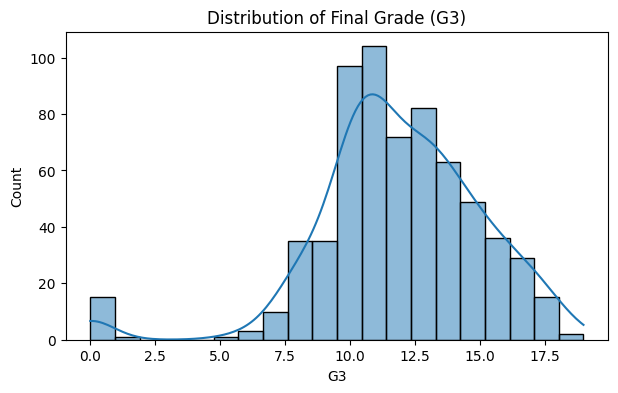

In [11]:
# histogram of G3, with continuous probability distribution over it
fig, ax = plt.subplots(figsize=(7,4))
sns.histplot(df["G3"], bins=20, kde=True, ax=ax)
ax.set_title("Distribution of Final Grade (G3)")
plt.show()

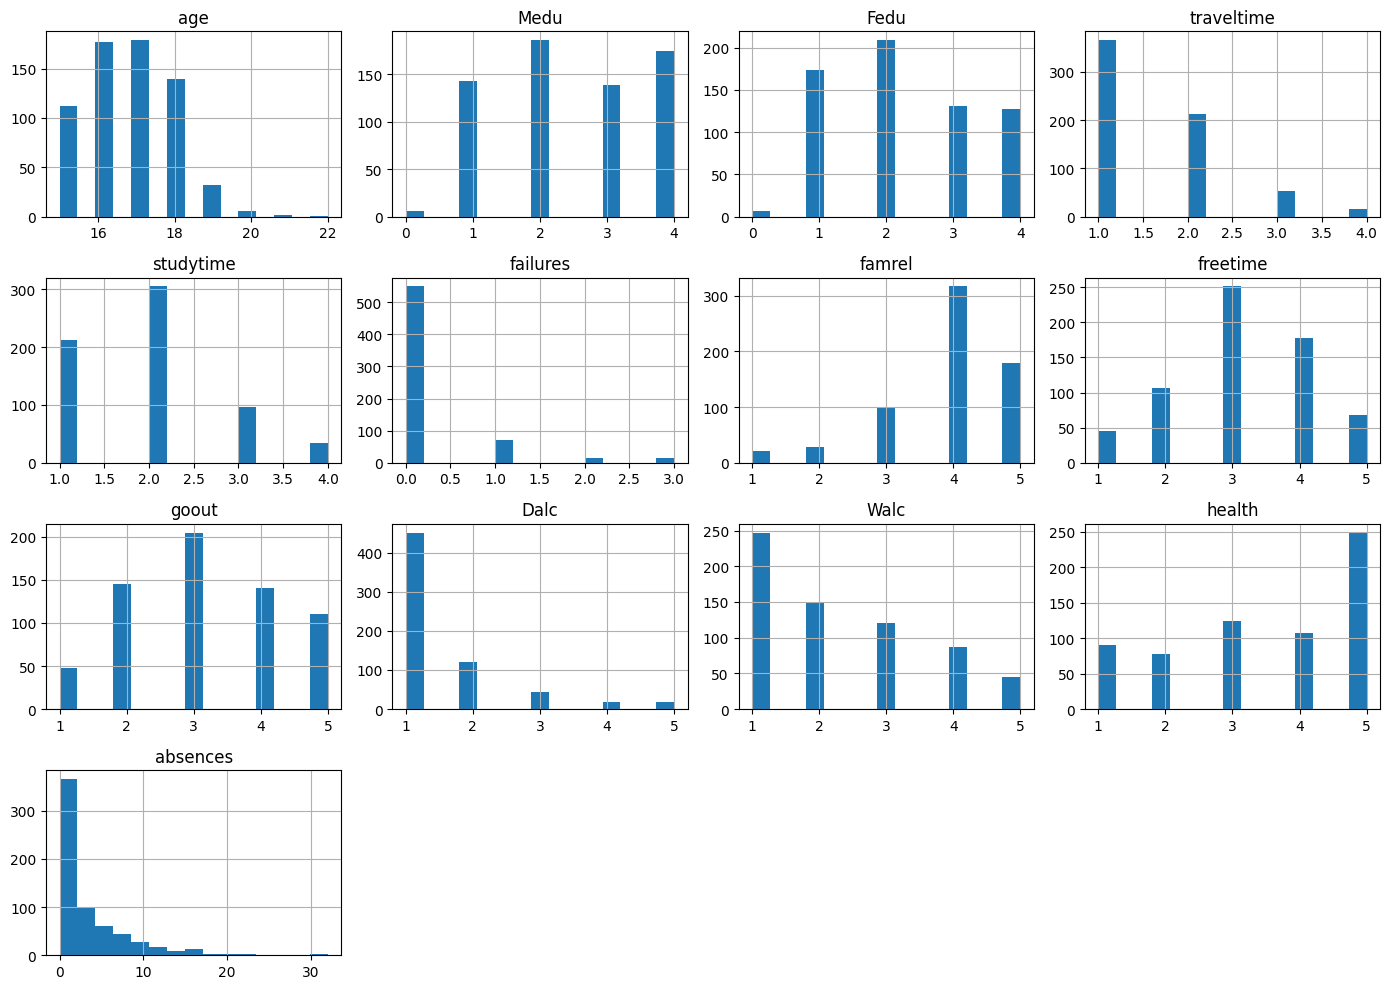

In [12]:
# checking the normality of the numeric variables
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ["G1", "G2", "G3"]] # remove target variables
df[numeric_cols].hist(figsize=(14, 10), bins=15)
plt.tight_layout()
plt.show()

### Analysis

Using `df.describe()` we see that most of the data is on the same scale apart from age (which is higher) and failure (which is lower) than the other numerical feature variables. From the **Distribution of Final Grades (G3)** we see that the data is left-skewed (the bulk of the higher count is on the right side). If we look at individual features and see their skewness, we see the following:

**Normal/Close to Normal**
- freetime
- gout

**Explanation:** Usually students try to balance free time/hanging out with friends with their education, or their fixed schedules dictate it, which naturally create a more normal shaped curve.

**Right Skewed**
- age
- traveltime
- studytime
- failures
- dalc
- walc
- absences

**Explanation:** For age, the oldest ages (19-20) are typically rare since more college students are fixed between 15-18. Additionally, for travel time and study time most students live near their high school and most don't study for heavy number of hours. Most students show up to class (especially with truancy laws) and very few high school students repeat courses, which makes absences and failures low. Lastly, most students rarely have time to drink on school weeks, and still drink less on the weekends, but the total scalar quantity goes up because of parties, hang outs, and events.

**Left Skewed**
- famrel
- health

**Explanation:** Must students are generally healthy and have good relations with their family hence why scoring for both of these is high.

**Neither/No Clear Pattern**
- Medu
- Fedu

**Explanation:** Most parents fall into two main groups: stopped after high school, stopped after college, which create two main clusters which result in those twin peaks on the graph.

### 3.3 Convert categorical attributes to numeric

In [13]:
cat_cols = df.select_dtypes(include=["object", "category"]).columns.to_list()
print("Categorical Columns:", cat_cols)

# convert each binary option to either 0 or 1
binary_col = [c for c in cat_cols if df[c].nunique() == 2]
for c in binary_col:
  df[c] = df[c].map({df[c].unique()[0]: 0, df[c].unique()[1]: 1})

# one-hot coding for multi-categories columns
multi_cat_col = [c for c in cat_cols if c not in binary_col]
df = pd.get_dummies(df, columns=multi_cat_col, drop_first=True)

df = df.apply(pd.to_numeric)
print(df.shape)
df.head()

Categorical Columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
(649, 42)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,...,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other
0,0,0,18,0,0,0,4,4,2,2,...,False,False,False,False,True,False,False,False,True,False
1,0,0,17,0,0,1,1,1,1,2,...,False,False,True,False,False,False,False,False,False,False
2,0,0,15,0,1,1,1,1,1,2,...,False,False,True,False,False,False,True,False,True,False
3,0,0,15,0,0,1,4,2,1,3,...,False,False,False,True,False,True,False,False,True,False
4,0,0,16,0,0,1,3,3,1,2,...,False,False,True,False,False,True,False,False,False,False


## 4. Correlation Analysis

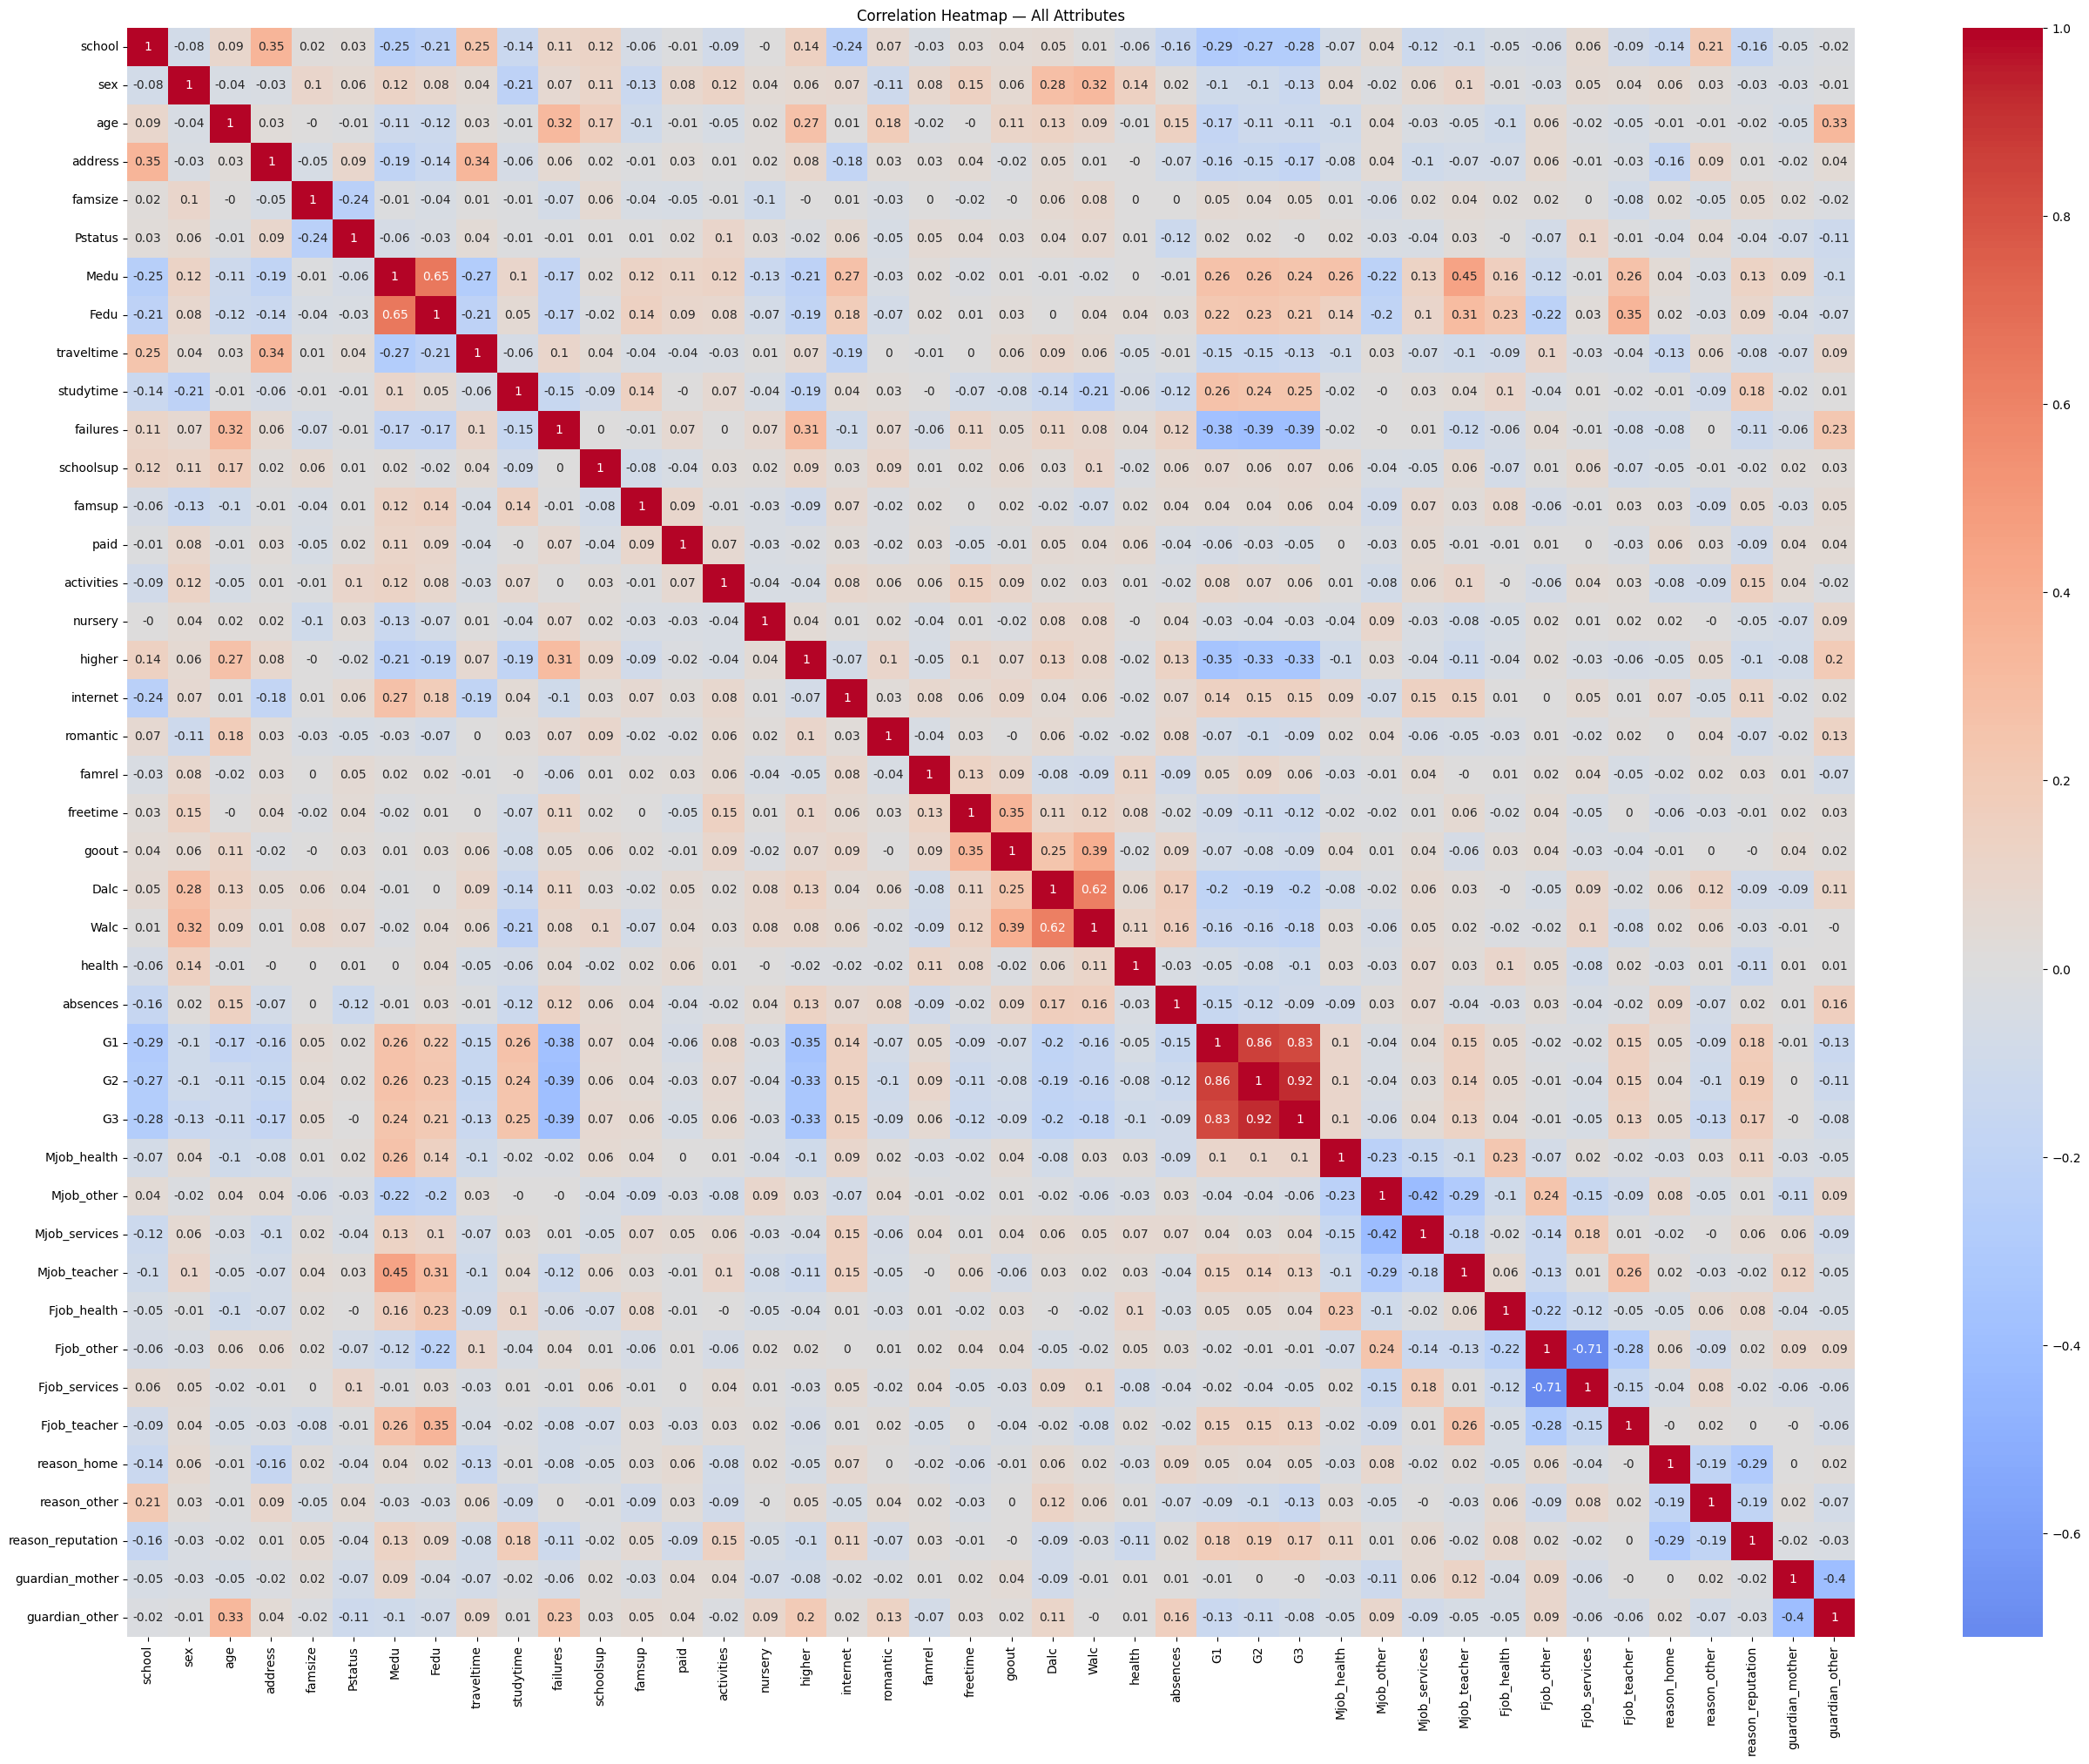

In [14]:
corr = df.corr(numeric_only=True).round(2)

plt.figure(figsize=(32, 24))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True)
plt.title("Correlation Heatmap — All Attributes")
plt.show()

In [15]:
target_corr = corr["G3"].sort_values(ascending=False)
print("Correlation of each attribute with G3 (final grade):")
print(target_corr)

Correlation of each attribute with G3 (final grade):
G3                   1.00
G2                   0.92
G1                   0.83
studytime            0.25
Medu                 0.24
Fedu                 0.21
reason_reputation    0.17
internet             0.15
Fjob_teacher         0.13
Mjob_teacher         0.13
Mjob_health          0.10
schoolsup            0.07
activities           0.06
famrel               0.06
famsup               0.06
reason_home          0.05
famsize              0.05
Mjob_services        0.04
Fjob_health          0.04
Pstatus             -0.00
guardian_mother     -0.00
Fjob_other          -0.01
nursery             -0.03
Fjob_services       -0.05
paid                -0.05
Mjob_other          -0.06
guardian_other      -0.08
absences            -0.09
romantic            -0.09
goout               -0.09
health              -0.10
age                 -0.11
freetime            -0.12
traveltime          -0.13
sex                 -0.13
reason_other        -0.13
address    

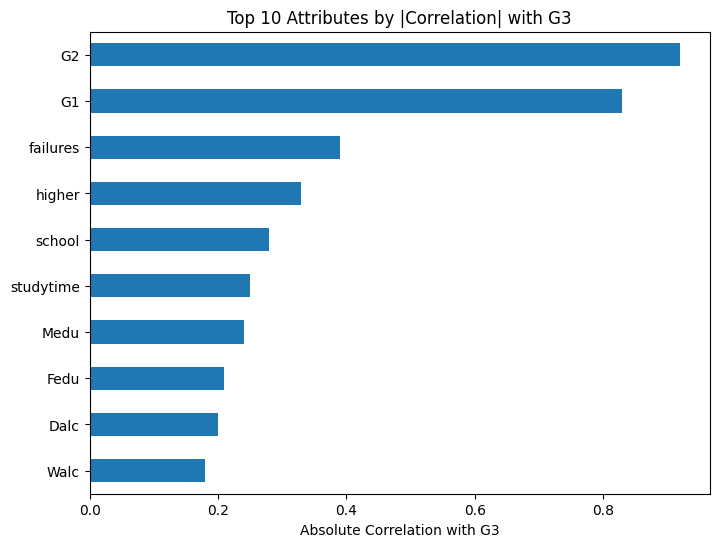

,G3
G2,0.92
G1,0.83
failures,0.39
higher,0.33
school,0.28
studytime,0.25
Medu,0.24
Fedu,0.21
Dalc,0.20
Walc,0.18


In [16]:
top_n = 10
top_features = target_corr.drop("G3").abs().sort_values(ascending=False).head(top_n)
plt.figure(figsize=(8,6))
top_features.sort_values().plot(kind="barh")
plt.title(f"Top {top_n} Attributes by |Correlation| with G3")
plt.xlabel("Absolute Correlation with G3")
plt.show()

top_features

In [17]:
# For Indetinfying Binary Variables
print(raw_df["sex"].unique())

print(raw_df["higher"].unique())

['F' 'M']
['yes' 'no']


## Analysis

 From our correlation heat math, we don't see a lot of high values in terms of positive and negative correlation with most values ranging between **0.2 to 0.39.** However, the highest correlations are the most obvious with **G1 and G2** because from the data set we are told that G3 is a combination of G1 and G2 because it is the final grade calculated from the first period grade and the second period grade. Thus we should assume a high level of correlation. They are mathematically linked.

 Other correlations also make sense. The pursuit of higher education usually means students are more willing to engage with education and thus produce better grades, more study time naturally leads to better grades, and the socioeconomic class with mother and father's education leads to better grades because of the they have access to tutors or other study resources with their increased income. In terms of the opposite side with negative correlation, failures make sense. As the number of failures go up, the grades naturally decrease. And similar reasonings can be applied with free time, alchohol content, and going out because these are all distractions from studying and learning.

### 4.1 Select a subset of important attributes

Pick the best attributes to move forward with. Originally, I was going to impose a harsh cutoff threshold, and not take any values less that 0.25 on the correlation matrix. However, it left me with values that logically did not look nice, so I decided to add back the parent's education.

In [18]:
SELECTED_FEATURES = list(top_features.index[:8])
print("Selected Features", SELECTED_FEATURES)

X = df[SELECTED_FEATURES].copy()
y = df["G3"].copy()

Selected Features ['G2', 'G1', 'failures', 'higher', 'school', 'studytime', 'Medu', 'Fedu']


## 5. Standardize / Normalize Attributes

As we said before, we are going to need to standardize this dataset since G1 and G2 operate with means around ~11 and failures operates with a mean around ~0.2 and even though G1 and G2 are going to do the heavy lifting of the model, we don't want it to overpower on the scale metric.  

In [19]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
X_scaled.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
G2,-2.189654e-17,1.000771,-3.974080,2.552006
G1,2.846550e-16,1.000771,-4.155470,2.770875
failures,3.284481e-17,1.000771,-0.374305,4.686612
higher,-4.926722e-17,1.000771,-0.344914,2.899275
school,0.000000e+00,1.000771,-0.730944,1.368094
studytime,9.579736e-17,1.000771,-1.122808,2.496576
Medu,-1.094827e-16,1.000771,-2.218124,1.310216
Fedu,-3.284481e-17,1.000771,-2.098682,1.540715


## 6. Train / Test Split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (519, 8)  Test shape: (130, 8)


## 7. Model 1 — Regularized Linear Regression via `SGDRegressor`

In [24]:
param_grid = {
    "loss": ["squared_error", "huber"],
    "penalty": ["l1", "l2", "elasticnet"],
    "alpha": [0.0001, 0.001, 0.01, 0.1],
    "learning_rate": ["invscaling", "adaptive"],
    "max_iter": [1000, 2000]
}

sgd = SGDRegressor(random_state=42)

grid = GridSearchCV(sgd, param_grid, scoring="r2", cv=5, n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best Score:", grid.best_score_)

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best Parameters: {'alpha': 0.01, 'learning_rate': 'adaptive', 'loss': 'squared_error', 'max_iter': 1000, 'penalty': 'l1'}
Best Score: 0.8479099767639232


In [25]:
# logs
results_log = pd.DataFrame(grid.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score")
results_log.head(15)

,params,mean_test_score,std_test_score,rank_test_score
60,"{'alpha': 0.01, 'learning_rate': 'adaptive', '...",0.847910,0.046398,1
63,"{'alpha': 0.01, 'learning_rate': 'adaptive', '...",0.847910,0.046398,1
62,"{'alpha': 0.01, 'learning_rate': 'adaptive', '...",0.847585,0.045681,3
65,"{'alpha': 0.01, 'learning_rate': 'adaptive', '...",0.847585,0.045681,3
64,"{'alpha': 0.01, 'learning_rate': 'adaptive', '...",0.847507,0.045579,5
61,"{'alpha': 0.01, 'learning_rate': 'adaptive', '...",0.847507,0.045579,5
36,"{'alpha': 0.001, 'learning_rate': 'adaptive', ...",0.847399,0.046038,7
39,"{'alpha': 0.001, 'learning_rate': 'adaptive', ...",0.847399,0.046038,7
41,"{'alpha': 0.001, 'learning_rate': 'adaptive', ...",0.847385,0.045959,9
38,"{'alpha': 0.001, 'learning_rate': 'adaptive', ...",0.847385,0.045959,9


In [26]:
best_sgd = grid.best_estimator_

y_train_pred = best_sgd.predict(X_train)
y_test_pred = best_sgd.predict(X_test)

def report_metrics(y_true, y_pred, label):
  mse = mean_squared_error(y_true, y_pred)
  rmse = np.sqrt(mse)
  mae = mean_absolute_error(y_true, y_pred)
  r2 = r2_score(y_true, y_pred)
  print(f"[{label}]  MSE={mse:.3f}  RMSE={rmse:.3f}  MAE={mae:.3f}  R^2={r2:.3f}")
  return mse, rmse, mae, r2

print("Best SGDRegressor Model")
train_metric = report_metrics(y_train, y_train_pred, "Train")
test_metric = report_metrics(y_test, y_test_pred, "Test")

Best SGDRegressor Model
[Train]  MSE=1.606  RMSE=1.267  MAE=0.799  R^2=0.847
[Test]  MSE=1.412  RMSE=1.188  MAE=0.750  R^2=0.855


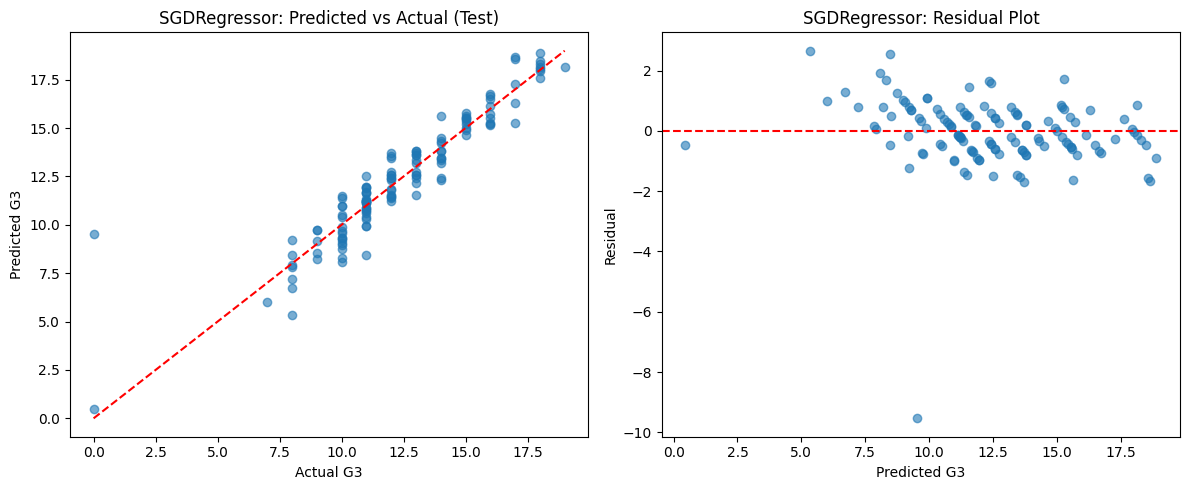

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))
ax[0].scatter(y_test, y_test_pred, alpha=0.6)
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set_xlabel("Actual G3"); ax[0].set_ylabel("Predicted G3")
ax[0].set_title("SGDRegressor: Predicted vs Actual (Test)")

residuals = y_test - y_test_pred
ax[1].scatter(y_test_pred, residuals, alpha=0.6)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted G3"); ax[1].set_ylabel("Residual")
ax[1].set_title("SGDRegressor: Residual Plot")
plt.tight_layout()
plt.show()

## Analysis

From this model, we see that our best parameters for our stochastic gradient descent have an adaptive learning rate, use the squared error first loss function, have a maximum iteration of 1000, use the L1 penalty, otherwise known as the lasso penalty, which means it can drive some values to zero, and it has the best alpha parameter of 0.01. We get that our test model has an R squared value of 0.85, which means that 85% of all the total variance can be explained with the parameters in our model, which is a very good high value to for us to have. Additionally, we have a very small MSE and MAE value indicating that all our predictions are not that far off from the actual values.

We can see from the graph that all the points on the predicted versus actual test model hug our red dashed line very closely. We do have one very big outlier when we predicted a value of close to 10 for the G3, but instead we got a actual value of zero. This could be explained based on dropouts. For example, if a student was a middle of the line level performer before they dropped out, the model still tries to predict their grades based on their G1 value and could see that their performance would indicate that they would get a 10 in G3, but in reality they got a zero because they never actually finished the class.

In the residual plot, we see that after 7, we form a nice cloud both above and below the line, which means that our residuals don't vary that much, and it seems very normalized, which we did after the standard scaling.

## 8. Model 2 — Ordinary Least Squares (`statsmodels`)


In [28]:
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

ols = sm.OLS(y_train, X_train_sm).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.847
Model:                            OLS   Adj. R-squared:                  0.845
Method:                 Least Squares   F-statistic:                     354.3
Date:                Sat, 19 Sep 2026   Prob (F-statistic):          9.40e-203
Time:                        15:42:31   Log-Likelihood:                -859.24
No. Observations:                 519   AIC:                             1736.
Df Residuals:                     510   BIC:                             1775.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.9188      0.056    211.932      0.0

We see a very good R squared and adjusted R squared values as well as a very low F statistic probability, which indicates that our model generally explains a lot of the variances in our dataset. However, when it comes to our individual parameters, all but G2 and G1 and school have incredibly high p values for our liking. And this could be explained due to multicollinearity. We know that G1 and G2 were going to be the bulk of our model because they are the best indicators for the final grade. And thus, parameters like higher and study time are already reflected in the G1 and G2 scores and thus don't add any new meaningful data. Same thing with mother and father's education. As we said, it's most likely that people marry within their own socioeconomic class. which means that they don't add any new information and they are correlated with one another.

Additionally, the standard deviations for all the values are small except that of G1 and G2, which is mostly because grades vary a lot more than any of these other metrics since they are on a higher scale. Most students have the same allocated number of hours for study time, which is why we're not going to see a lot of variation in how much each student actually studies as opposed to their grades.

In [30]:
y_train_pred_ols = ols.predict(X_train_sm)
y_test_pred_ols = ols.predict(X_test_sm)

print("=== Plain OLS ===")
report_metrics(y_train, y_train_pred_ols, "Train")
report_metrics(y_test, y_test_pred_ols, "Test")

=== Plain OLS ===
[Train]  MSE=1.605  RMSE=1.267  MAE=0.801  R^2=0.847
[Test]  MSE=1.424  RMSE=1.193  MAE=0.755  R^2=0.854


(1.424279763798189,
 np.float64(1.1934319267550155),
 0.7549822171736139,
 0.8539457294228939)

### 8.2 Regularized OLS via `fit_regularized()`

In [35]:
reg_results = []

for alpha in [0.0, 0.01, 0.1, 0.5, 1.0]:
  for l1_wt in [0.0, 0.5, 1.0]:
    reg_model = sm.OLS(y_train, X_train_sm).fit_regularized(alpha=alpha, L1_wt=l1_wt)
    preds = reg_model.predict(X_test_sm)
    mse = mean_squared_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    reg_results.append({"alpha": alpha, "L1_wt": l1_wt, "test_MSE": mse, "test_R2": r2})

reg_results_df = pd.DataFrame(reg_results).sort_values("test_R2", ascending=False)
reg_results_df.head(15)

,alpha,L1_wt,test_MSE,test_R2
8,0.10,1.0,1.326385,0.863984
5,0.01,1.0,1.405914,0.855829
4,0.01,0.5,1.410542,0.855355
3,0.01,0.0,1.420587,0.854324
1,0.00,0.5,1.424280,0.853946
2,0.00,1.0,1.424280,0.853946
0,0.00,0.0,1.424280,0.853946
7,0.10,0.5,1.693800,0.826307
11,0.50,1.0,1.703456,0.825317
6,0.10,0.0,2.519616,0.741623


In [36]:
best_row = reg_results_df.iloc[0]
best_ols_reg = sm.OLS(y_train, X_train_sm).fit_regularized(alpha=best_row["alpha"], L1_wt=best_row["L1_wt"])

print("Best alpha / L1_wt:", best_row["alpha"], best_row["L1_wt"])
print(pd.Series(best_ols_reg.params, index=X_train_sm.columns))

Best alpha / L1_wt: 0.1 1.0
const        11.813929
G2            2.507573
G1            0.421604
failures     -0.020393
higher        0.000000
school       -0.084415
studytime     0.000000
Medu          0.000000
Fedu          0.000000
dtype: float64


## Analysis

We see that the regularization definitely improved the R squared and MSC values than the non-regularization models, making it about 0.86 and 1.3 respectively. Additionally, like we expected, all the parameters that have incredibly high p-value were driven towards zero with our Lasso L1 penalty, so higher study time, mother and father's education were all given zero values and such. And interestingly, G2 was given a higher weightage than G1, possibly because students might grow more towards the end of the year and thus their G2 grades are stronger and more indicative of how they will perform in their finals.

## 9. Model Comparison & Overall Results

In [37]:
comparison = pd.DataFrame({
    "Model": ["SGDRegressor (best)", "OLS (plain)", "OLS (regularized, best)"],
    "Test_R2": [
        r2_score(y_test, y_test_pred),
        r2_score(y_test, y_test_pred_ols),
        best_row["test_R2"],
    ],
    "Test_RMSE": [
        np.sqrt(mean_squared_error(y_test, y_test_pred)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_ols)),
        np.sqrt(best_row["test_MSE"]),
    ],
})
comparison

,Model,Test_R2,Test_RMSE
0,SGDRegressor (best),0.855256,1.188067
1,OLS (plain),0.853946,1.193432
2,"OLS (regularized, best)",0.863984,1.151688


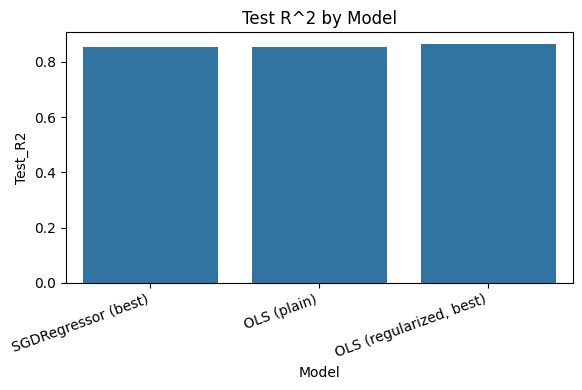

In [43]:
# since the r^2 values are so similar, i want to really zoom in and focus on the differences
plt.figure(figsize=(6,4))
sns.barplot(data=comparison, x="Model", y="Test_R2")
plt.xticks(rotation=20, ha="right")
plt.title("Test R^2 by Model")
plt.tight_layout()
plt.show()